In [10]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
import umap

форма данных: (569, 30)
классы: [np.str_('malignant'), np.str_('benign')]  (0 = malignant, 1 = benign)
распределение классов: [212 357]
train: (426, 30), test: (143, 30)
baseline
accuracy: 0.9580
время обучения: 0.6364 c
исходных признаков: 30
после PCA(0.95):    10
сжатие: 66.7%

PCA(0.95) + RandomForest
accuracy: 0.9580
время обучения: 0.6446 c
модель                        accuracy    время (с)
baseline (30 признаков)       0.9580      0.6364
PCA(0.95) + RF                0.9580      0.6446
качество не изменилось.
размерность уменьшилась в 3.0 раз(а).


c:\anaconda3\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\anaconda3\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


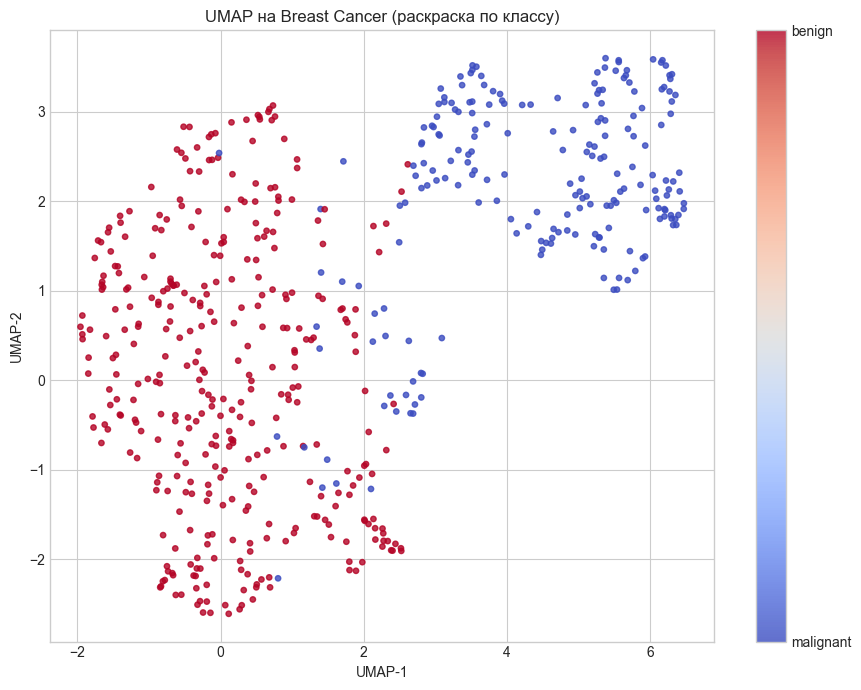

ModuleNotFoundError: No module named '_posixsubprocess'

In [14]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
np.random.seed(42)


data = load_breast_cancer()
X = data.data
y = data.target

print(f"форма данных: {X.shape}")
print(f"классы: {list(data.target_names)}  (0 = malignant, 1 = benign)")
print(f"распределение классов: {np.bincount(y)}")


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"train: {X_train.shape}, test: {X_test.shape}")


rf_baseline = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

t0 = time.time()
rf_baseline.fit(X_train, y_train)
train_time_baseline = time.time() - t0

y_pred_baseline = rf_baseline.predict(X_test)
acc_baseline = accuracy_score(y_test, y_pred_baseline)

print("baseline")
print(f"accuracy: {acc_baseline:.4f}")
print(f"время обучения: {train_time_baseline:.4f} c")



scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"исходных признаков: {X_train.shape[1]}")
print(f"после PCA(0.95):    {X_train_pca.shape[1]}")
print(f"сжатие: {(1 - X_train_pca.shape[1] / X_train.shape[1]) * 100:.1f}%")


rf_pca = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

t0 = time.time()
rf_pca.fit(X_train_pca, y_train)
train_time_pca = time.time() - t0

y_pred_pca = rf_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, y_pred_pca)

print("\nPCA(0.95) + RandomForest")
print(f"accuracy: {acc_pca:.4f}")
print(f"время обучения: {train_time_pca:.4f} c")


print("=" * 55)
print(f"{'модель':<30}{'accuracy':<12}{'время (с)'}")
print("=" * 55)
print(f"{'baseline (30 признаков)':<30}{acc_baseline:<12.4f}{train_time_baseline:.4f}")
print(f"{'PCA(0.95) + RF':<30}{acc_pca:<12.4f}{train_time_pca:.4f}")
print("=" * 55)

delta = acc_pca - acc_baseline
if delta < -1e-4:
    print(f"качество упало на {abs(delta) * 100:.2f} п.п.")
elif delta > 1e-4:
    print(f"качество выросло на {delta * 100:.2f} п.п.")
else:
    print("качество не изменилось.")

print(f"размерность уменьшилась в {X_train.shape[1] / X_train_pca.shape[1]:.1f} раз(а).")


X_all_scaled = StandardScaler().fit_transform(X)

reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_all_scaled)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap='coolwarm', s=15, alpha=0.8)
plt.title('UMAP на Breast Cancer (раскраска по классу)')
plt.xlabel('UMAP-1')
plt.ylabel('UMAP-2')
cbar = plt.colorbar(scatter)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(data.target_names)
plt.tight_layout()
plt.show()


pipe_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

pipe_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

cv_baseline = cross_val_score(pipe_baseline, X, y, cv=5, scoring='accuracy', n_jobs=-1)
cv_pca = cross_val_score(pipe_pca, X, y, cv=5, scoring='accuracy', n_jobs=-1)

print(f"CV baseline (30 признаков):  {cv_baseline.mean():.4f} ± {cv_baseline.std():.4f}")
print(f"CV PCA(0.95) + RF:           {cv_pca.mean():.4f} ± {cv_pca.std():.4f}")
print(f"\nдоля сохранённой дисперсии: {pca.explained_variance_ratio_.sum():.4f}")